# Tomato Leaf Disease Detection with a CNN Feature Extractor and an MLP Head

**Pipeline**

```
INPUT IMAGE → PREPROCESSING (RGB, 224×224, ImageNet normalisation)
            → CNN FEATURE EXTRACTOR (ResNet18 trunk, ImageNet-pretrained, layer3+layer4 fine-tuned)
            → FEATURE VECTOR (512-d, global average pooling)
            → MLP HEAD (Linear 512→256, ReLU, Dropout 0.3, Linear 256→C)
            → SOFTMAX → DISEASE CLASS + CLASS PROBABILITIES
            → GRAD-CAM (layer4) for explainability
```

This notebook reproduces the full workflow: dataset download, inspection, leak-free stratified splitting,
model construction, training, test evaluation, Grad-CAM and inference on unseen images. Every cell calls the
project's `src/` modules so the notebook and the scripts share one implementation.

> **Runtime note.** Training takes ~10–15 minutes on an Apple M-series GPU (MPS). The training cell runs the
> full training loop only when `models/best_model.pth` does not exist (or when `FORCE_RETRAIN = True`);
> otherwise it loads the saved history so the notebook runs top-to-bottom in a few minutes.

## 2. Imports and environment checks

In [1]:
import json, os, sys, time
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as IPyImage, display

from src.utils import (MODELS_DIR, PLOTS_DIR, RESULTS_DIR, SPLITS_DIR, PROCESSED_DIR,
                       environment_report, get_device, load_json, set_seed, absolute_from_project)

set_seed(42)
DEVICE = get_device()
ENV = environment_report(DEVICE)
print(json.dumps(ENV, indent=2))
assert ENV["selected_device"] in ("mps", "cpu", "cuda")

{
  "python": "3.12.15",
  "platform": "macOS-26.5.1-arm64-arm-64bit",
  "machine": "arm64",
  "torch": "2.15.0",
  "torchvision": "0.29.2",
  "mps_built": true,
  "mps_available": true,
  "cuda_available": false,
  "selected_device": "mps",
  "cpu_count": 10
}


## 3. Dataset download

Source: **PlantVillage** on Kaggle (`emmarex/plantdisease`, https://www.kaggle.com/datasets/emmarex/plantdisease),
downloaded with `kagglehub`. The dataset is public, so no credentials were needed; a cached copy is reused on re-runs.

In [2]:
from src.download import download_dataset, find_class_root, record_source

download_path = download_dataset()
class_root = find_class_root(download_path)
source_info = record_source(download_path, class_root)
print("Download path:", download_path)
print("Class root   :", class_root)

Download path: /Users/sidd/Downloads/Tomato_Leaf_Disease_Detection/data/raw/kagglehub_cache/datasets/emmarex/plantdisease/versions/1
Class root   : /Users/sidd/Downloads/Tomato_Leaf_Disease_Detection/data/raw/kagglehub_cache/datasets/emmarex/plantdisease/versions/1/PlantVillage


## 4. Dataset extraction

`kagglehub` extracts the archive automatically. The archive contains `PlantVillage/` and an identical nested
`PlantVillage/PlantVillage/` copy; `find_class_root` picks the shallowest folder so images are indexed once.
Non-tomato folders (Pepper, Potato) are listed here for transparency and excluded from everything that follows.

In [3]:
folders = sorted(d for d in os.listdir(class_root) if (class_root / d).is_dir() and d != "PlantVillage")
rows = [{"folder": d, "is_tomato": d.startswith("Tomato"),
         "files": sum(1 for _ in (class_root / d).iterdir())} for d in folders]
folder_df = pd.DataFrame(rows)
display(folder_df)
print("Tomato folders:", int(folder_df.is_tomato.sum()), "| excluded non-tomato folders:", int((~folder_df.is_tomato).sum()))

,folder,is_tomato,files
0,Pepper__bell___Bacterial_spot,False,997
1,Pepper__bell___healthy,False,1478
2,Potato___Early_blight,False,1000
3,Potato___Late_blight,False,1000
4,Potato___healthy,False,152
5,Tomato_Bacterial_spot,True,2127
6,Tomato_Early_blight,True,1000
7,Tomato_Late_blight,True,1909
8,Tomato_Leaf_Mold,True,952
9,Tomato_Septoria_leaf_spot,True,1771


Tomato folders: 10 | excluded non-tomato folders: 5


## 5. Dataset inspection

`src.dataset.prepare_dataset` indexes every tomato image in parallel: it fully decodes each file (corrupt
detection), records resolution/mode/format, and computes an MD5 (exact duplicates) and a 64-bit dHash
(near-duplicates, Hamming distance ≤ 4). Class names are derived from the folder names.

10 tomato classes:
  Tomato_Bacterial_spot                            -> Bacterial spot
  Tomato_Early_blight                              -> Early blight
  Tomato_Late_blight                               -> Late blight
  Tomato_Leaf_Mold                                 -> Leaf Mold
  Tomato_Septoria_leaf_spot                        -> Septoria leaf spot
  Tomato_Spider_mites_Two_spotted_spider_mite      -> Spider mites Two spotted spider mite
  Tomato__Target_Spot                              -> Target Spot
  Tomato__Tomato_YellowLeaf__Curl_Virus            -> Tomato Yellow Leaf Curl Virus
  Tomato__Tomato_mosaic_virus                      -> Tomato mosaic virus
  Tomato_healthy                                   -> Healthy

Indexed files: 16011 | corrupt/unreadable: 0 | usable: 16011


'No corrupt images found.'

Usable images: 16011, classes: 10, imbalance ratio: 8.6
Dimensions: {'256x256': 16011}
Plots saved to /Users/sidd/Downloads/Tomato_Leaf_Disease_Detection/results/plots


,images,share_%
Tomato_Bacterial_spot,2127,13.28
Tomato_Early_blight,1000,6.25
Tomato_Late_blight,1909,11.92
Tomato_Leaf_Mold,952,5.95
Tomato_Septoria_leaf_spot,1771,11.06
Tomato_Spider_mites_Two_spotted_spider_mite,1676,10.47
Tomato__Target_Spot,1404,8.77
Tomato__Tomato_YellowLeaf__Curl_Virus,3208,20.04
Tomato__Tomato_mosaic_virus,373,2.33
Tomato_healthy,1591,9.94


Imbalance ratio (max/min): 8.6
Resolutions: {'256x256': 16011} | modes: {'RGB': 16011} | formats: {'JPEG': 16011}


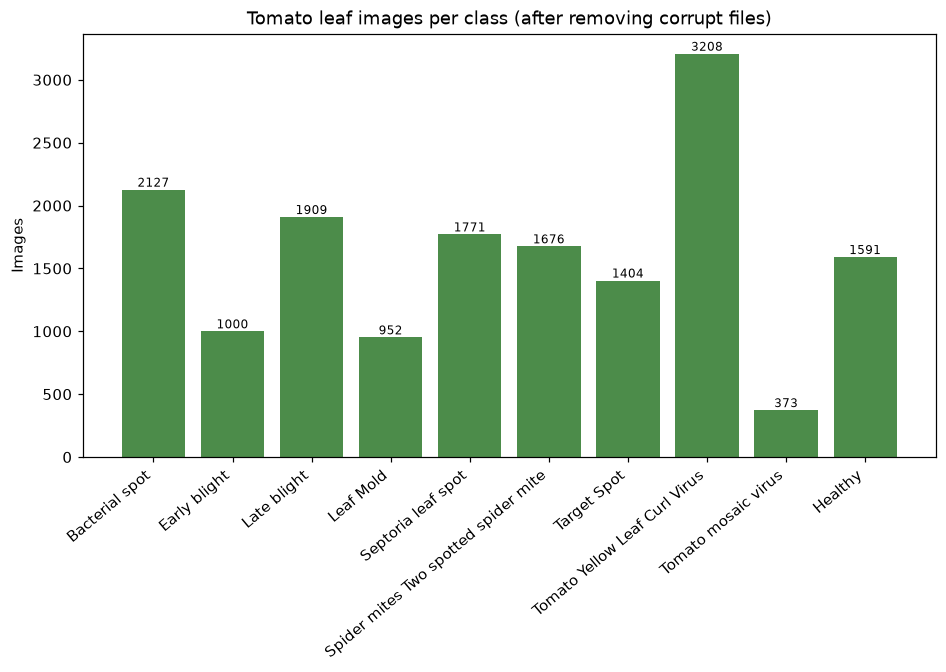

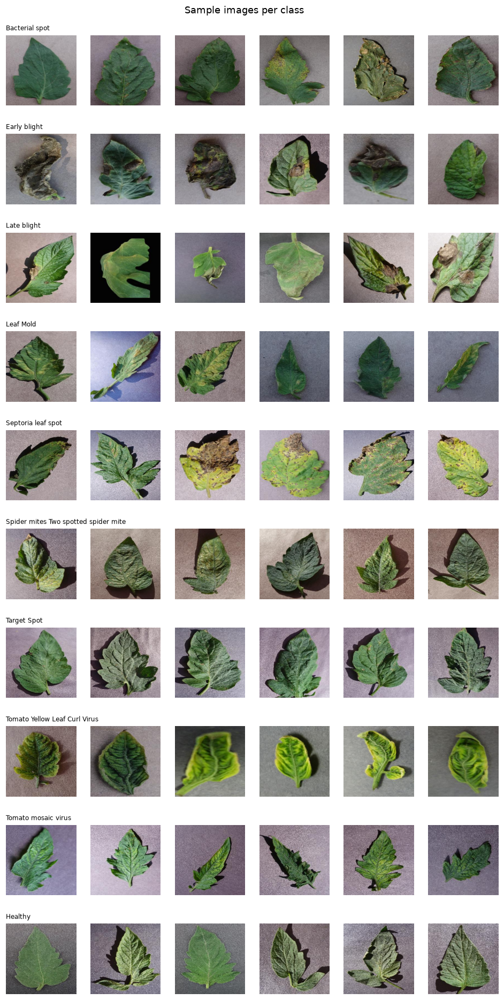

In [4]:
from src.dataset import prepare_dataset, discover_tomato_classes, display_name
from src import explore

if not (SPLITS_DIR / "test.csv").exists():
    prepare_dataset(seed=42, workers=8)

classes = discover_tomato_classes(class_root)
print(f"{len(classes)} tomato classes:")
for c in classes:
    print(f"  {c:48s} -> {display_name(c)}")

index = pd.read_csv(PROCESSED_DIR / "image_index.csv")
clean = pd.read_csv(PROCESSED_DIR / "image_index_clean.csv")
print(f"\nIndexed files: {len(index)} | corrupt/unreadable: {(~index.ok).sum()} | usable: {len(clean)}")
display(index.loc[~index.ok, ["path", "error"]] if (~index.ok).any() else "No corrupt images found.")

explore.main()  # regenerates class distribution, dimension, sample and split plots
summary = load_json(RESULTS_DIR / "dataset_summary.json")
counts = pd.Series(summary["class_counts"]).rename("images").to_frame()
counts["share_%"] = (100 * counts.images / counts.images.sum()).round(2)
display(counts)
print("Imbalance ratio (max/min):", summary["imbalance_ratio_max_over_min"])
print("Resolutions:", summary["image_dimensions"], "| modes:", summary["image_modes"], "| formats:", summary["image_formats"])
display(IPyImage(filename=str(PLOTS_DIR / "class_distribution.png")))
display(IPyImage(filename=str(PLOTS_DIR / "sample_images.png"), width=900))

## 6. Data preprocessing

* Convert to RGB, resize to 224×224, normalise with ImageNet mean/std (required by the pretrained ResNet18).
* **Training only**: RandomResizedCrop (scale 0.75–1), horizontal + vertical flips, ±15° rotation, mild colour jitter.
* Validation / test / inference use the deterministic resize + normalise transform only.

Train transform:
 Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.75, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.02, 0.02))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

Eval transform:
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

Eval tensor shape: (3, 224, 224) | value range: [-1.98, 1.09]


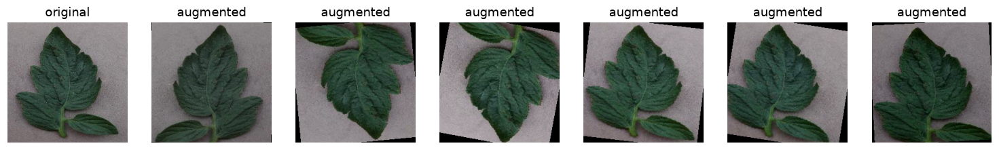

In [5]:
from src.preprocessing import get_train_transforms, get_eval_transforms, load_image, denormalize, IMAGENET_MEAN, IMAGENET_STD

print("Train transform:\n", get_train_transforms(), "\n\nEval transform:\n", get_eval_transforms())
sample_path = absolute_from_project(clean.iloc[0].path)
img = load_image(sample_path)
x_eval = get_eval_transforms()(img)
print("\nEval tensor shape:", tuple(x_eval.shape), "| value range: [%.2f, %.2f]" % (x_eval.min(), x_eval.max()))

fig, axes = plt.subplots(1, 7, figsize=(17, 2.8))
axes[0].imshow(img); axes[0].set_title("original"); axes[0].axis("off")
torch.manual_seed(0)
for ax in axes[1:]:
    ax.imshow(denormalize(get_train_transforms()(img))); ax.set_title("augmented"); ax.axis("off")
display(fig); plt.close(fig)

## 7. Train / validation / test splitting (70 / 15 / 15)

Splitting is **stratified by class and grouped by duplicate cluster** (seed 42): all exact or near-duplicate
images of a leaf land in the same subset, so no image (or near copy) can appear in two subsets. The test set
is never used for training, augmentation selection, hyper-parameter tuning or early stopping.

Counts   : {'train': 11208, 'val': 2404, 'test': 2399}
Fractions: {'train': 0.7, 'val': 0.1501, 'test': 0.1498}
Overlaps : {'train-val': {'shared_paths': 0, 'shared_groups': 0, 'shared_md5': 0}, 'train-test': {'shared_paths': 0, 'shared_groups': 0, 'shared_md5': 0}, 'val-test': {'shared_paths': 0, 'shared_groups': 0, 'shared_md5': 0}}
Leakage-free: True
Duplicates: {'images': 16011, 'unique_groups': 15977, 'groups_with_duplicates': 34, 'images_in_duplicate_groups': 68, 'exact_duplicate_images': 28, 'near_duplicate_images': 40, 'largest_group_size': 2, 'groups_spanning_multiple_classes': 2, 'dhash_hamming_threshold': 4}


count           fraction          \
                                            train  val test    train     val   
Tomato_Bacterial_spot                        1489  319  319   0.7000  0.1500   
Tomato_Early_blight                           700  150  150   0.7000  0.1500   
Tomato_Late_blight                           1336  287  286   0.6998  0.1503   
Tomato_Leaf_Mold                              666  143  143   0.6996  0.1502   
Tomato_Septoria_leaf_spot                    1240  266  265   0.7002  0.1502   
Tomato_Spider_mites_Two_spotted_spider_mite  1173  252  251   0.6999  0.1504   
Tomato__Target_Spot                           983  211  210   0.7001  0.1503   
Tomato__Tomato_YellowLeaf__Curl_Virus        2246  481  481   0.7001  0.1499   
Tomato__Tomato_mosaic_virus                   261   56   56   0.6997  0.1501   
Tomato_healthy                               1114  239  238   0.7002  0.1502   

                                                     
                                               test  
Tomato_Bacterial_spot                        0.1500  
Tomato_Early_blight                          0.1500  
Tomato_Late_blight                           0.1498  
Tomato_Leaf_Mold                             0.1502  
Tomato_Septoria_leaf_spot                    0.1496  
Tomato_Spider_mites_Two_spotted_spider_mite  0.1498  
Tomato__Target_Spot                          0.1496  
Tomato__Tomato_YellowLeaf__Curl_Virus        0.1499  
Tomato__Tomato_mosaic_virus                  0.1501  
Tomato_healthy                               0.1496

train 11208 rows, 10 classes
val 2404 rows, 10 classes
test 2399 rows, 10 classes


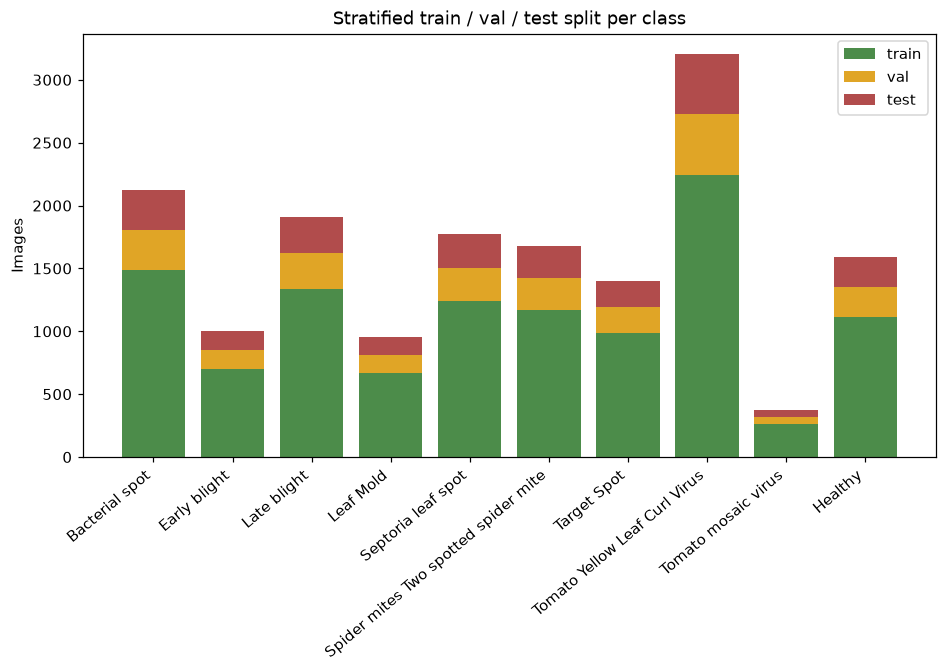

In [6]:
split_report = load_json(SPLITS_DIR / "split_summary.json")
print("Counts   :", split_report["counts"])
print("Fractions:", split_report["fractions"])
print("Overlaps :", split_report["overlaps"])
print("Leakage-free:", split_report["leakage_free"])
print("Duplicates:", split_report["duplicates"])
per_class = pd.DataFrame(split_report["per_class_counts"]).T
per_class_frac = pd.DataFrame(split_report["per_class_fractions"]).T
display(pd.concat({"count": per_class, "fraction": per_class_frac}, axis=1))

for s in ("train", "val", "test"):
    d = pd.read_csv(SPLITS_DIR / f"{s}.csv"); print(s, len(d), "rows,", d.label.nunique(), "classes")
assert split_report["leakage_free"]
display(IPyImage(filename=str(PLOTS_DIR / "split_distribution.png")))

## 8. CNN architecture

**Why transfer learning with ResNet18?** ~16k images of 256×256 leaves is small for training a deep CNN from
scratch, and the hardware is a 16 GB MacBook (Apple MPS). ImageNet-pretrained filters give strong generic
edge/texture features, converge in a few epochs and generalise better than a from-scratch network of the same
size. ResNet18 (11.2M parameters) is the smallest standard residual network, so it trains quickly on MPS.

| Component | Layers | Pretrained? | Trained here? |
|---|---|---|---|
| Stem (`conv1`, `bn1`, ReLU, maxpool) | 7×7 conv s2 + BN + 3×3 maxpool | ImageNet | **frozen** (BN in eval mode) |
| `layer1`, `layer2` | 2 BasicBlocks each (64, 128 channels) | ImageNet | **frozen** |
| `layer3`, `layer4` | 2 BasicBlocks each (256, 512 channels) | ImageNet | **fine-tuned** (lr 1e-4) |
| Global average pooling | AdaptiveAvgPool2d(1) → flatten | – | – |
| MLP head | Linear 512→256, ReLU, Dropout 0.3, Linear 256→C | random init | **trained** (lr 1e-3) |

Every CNN stage contains convolutions, batch normalisation, ReLU and (via strides / maxpool) pooling. The
feature extractor output is a 512-d vector; the MLP head produces one logit per class and softmax is applied
only at inference. Loss: `CrossEntropyLoss` with inverse-sqrt class weights and label smoothing 0.05.

In [7]:
from src.model import ModelConfig, build_model, model_summary, trace_shapes, parameter_breakdown

mapping = load_json(MODELS_DIR / "class_mapping.json")
config = ModelConfig(num_classes=mapping["num_classes"])
model = build_model(config)
print(model)

TomatoLeafCNN(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bi

## 9. Model summary: tensor shapes at every stage and parameter counts

In [8]:
print(model_summary(model))
params = parameter_breakdown(model)
display(pd.DataFrame(params).T)

Backbone: resnet18 (ImageNet pretrained=True)
Trainable backbone stages: ['layer3', 'layer4']; frozen: ['conv1', 'bn1', 'layer1', 'layer2']
MLP head: Linear(512->256) -> ReLU -> Dropout(0.3) -> Linear(256->10)

Tensor shapes (batch of 1):
  input                            [1, 3, 224, 224]
  stem (conv1+bn+relu+maxpool)     [1, 64, 56, 56]
  layer1                           [1, 64, 56, 56]
  layer2                           [1, 128, 28, 28]
  layer3                           [1, 256, 14, 14]
  layer4 (Grad-CAM target)         [1, 512, 7, 7]
  global avg pool + flatten        [1, 512]
  head.fc1 + ReLU (+Dropout)       [1, 256]
  head.fc2 logits                  [1, 10]

Parameters:
  stem     total=      9,536  trainable=          0  frozen=      9,536
  layer1   total=    147,968  trainable=          0  frozen=    147,968
  layer2   total=    525,568  trainable=          0  frozen=    525,568
  layer3   total=  2,099,712  trainable=  2,099,712  frozen=          0
  layer4   total=  8,

,total,trainable,frozen
stem,9536,0,9536
layer1,147968,0,147968
layer2,525568,0,525568
layer3,2099712,2099712,0
layer4,8393728,8393728,0
head,133898,133898,0
total,11310410,10627338,683072


## 10. Training

AdamW (backbone lr 1e-4, head lr 1e-3, weight decay 1e-4), `ReduceLROnPlateau` on validation macro-F1,
early stopping (patience 4) on validation macro-F1, batch size 32, up to 15 epochs, seed 42. The best
checkpoint is selected on **validation** macro-F1 only. Training writes `models/best_model.pth`,
`models/model_config.json`, `results/training_history.csv` and `results/training_summary.json`.

In [9]:
from src.train import train, parse_args

FORCE_RETRAIN = False
if FORCE_RETRAIN or not (MODELS_DIR / "best_model.pth").exists():
    training_summary = train(parse_args(["--epochs", "15", "--batch-size", "32", "--num-workers", "6", "--patience", "4"]))
else:
    training_summary = load_json(RESULTS_DIR / "training_summary.json")
    print("Using existing checkpoint; training summary from the saved run:")
print(json.dumps({k: training_summary[k] for k in ("device", "epochs_run", "best_epoch", "best_val_macro_f1",
                                                     "best_val_acc", "total_training_seconds", "mean_epoch_seconds")}, indent=2))
print("Hyper-parameters:", json.dumps({k: v for k, v in training_summary["hyperparameters"].items()
                                       if k not in ("class_weights", "train_class_counts")}, indent=2))

Using existing checkpoint; training summary from the saved run:
{
  "device": "mps",
  "epochs_run": 15,
  "best_epoch": 15,
  "best_val_macro_f1": 0.9974096042171825,
  "best_val_acc": 0.9970881863560732,
  "total_training_seconds": 1006.7775809764862,
  "mean_epoch_seconds": 67.06741355260213
}
Hyper-parameters: {
  "epochs": 15,
  "batch_size": 32,
  "num_workers": 6,
  "img_size": 224,
  "hidden_dim": 256,
  "dropout": 0.3,
  "trainable_stages": [
    "layer3",
    "layer4"
  ],
  "backbone_lr": 0.0001,
  "head_lr": 0.001,
  "weight_decay": 0.0001,
  "label_smoothing": 0.05,
  "patience": 4,
  "min_delta": 0.0001,
  "seed": 42,
  "device": null,
  "smoke": false,
  "optimizer": "AdamW",
  "scheduler": "ReduceLROnPlateau(max, factor=0.5, patience=2) on val macro-F1",
  "loss": "CrossEntropyLoss(inverse-sqrt class weights, label_smoothing=0.05)"
}


## 11. Training graphs

,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1,lr_backbone,lr_head,epoch_seconds
0,1,0.7265,0.8711,0.8475,0.5101,0.9438,0.9378,0.0001,0.0010,101.1933
1,2,0.4929,0.9552,0.9480,0.4425,0.9759,0.9758,0.0001,0.0010,46.5571
2,3,0.4458,0.9692,0.9628,0.3978,0.9867,0.9879,0.0001,0.0010,57.4560
3,4,0.4235,0.9751,0.9727,0.3963,0.9854,0.9867,0.0001,0.0010,61.6638
4,5,0.4089,0.9801,0.9774,0.3979,0.9842,0.9837,0.0001,0.0010,64.3996
5,6,0.3891,0.9868,0.9857,0.3843,0.9867,0.9855,0.0000,0.0005,57.3598
6,7,0.3670,0.9927,0.9924,0.3608,0.9942,0.9939,0.0000,0.0005,68.2836
7,8,0.3624,0.9933,0.9924,0.3586,0.9954,0.9958,0.0000,0.0005,66.5972
8,9,0.3591,0.9945,0.9940,0.3571,0.9950,0.9947,0.0000,0.0005,61.8959
9,10,0.3579,0.9934,0.9932,0.3541,0.9958,0.9957,0.0000,0.0005,66.6982


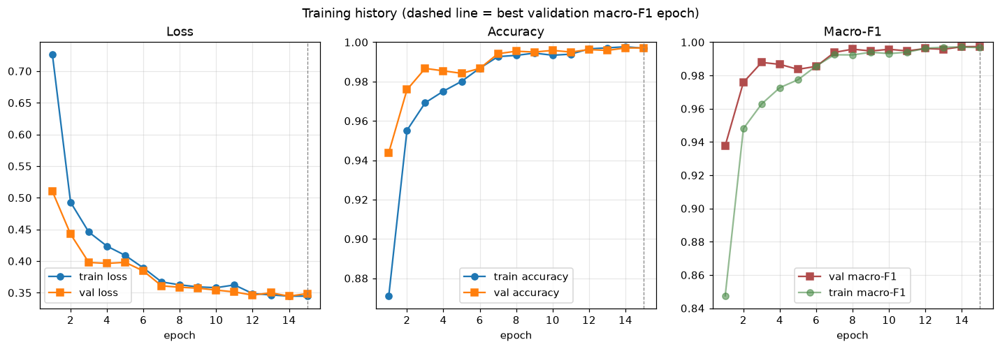

Selected checkpoint = epoch 15: val acc 0.9971, val macro-F1 0.9974, train acc 0.9970; train-val loss gap -0.0041
Epochs where validation loss exceeded training loss: [13, 15]


In [10]:
history = pd.read_csv(RESULTS_DIR / "training_history.csv")
display(history.round(4))
display(IPyImage(filename=str(PLOTS_DIR / "training_curves.png")))
best = history.loc[history.epoch == training_summary["best_epoch"]].iloc[0]
print(f"Selected checkpoint = epoch {int(best.epoch)}: val acc {best.val_acc:.4f}, val macro-F1 {best.val_macro_f1:.4f}, "
      f"train acc {best.train_acc:.4f}; train-val loss gap {best.train_loss - best.val_loss:+.4f}")
worse = history[history.val_loss > history.train_loss].epoch.tolist()
print("Epochs where validation loss exceeded training loss:", worse or "none")

**Reading the curves.** Training ran for 15 epochs (16.8 min in total,
67 s per epoch on average; the first epoch is slower because of one-off kernel
compilation and DataLoader start-up). The validation loss lies *below* the training loss for most epochs
(it exceeds it only at epochs [13, 15]); this is expected because the training loss is computed
with augmentation, dropout, class weights and label smoothing active, whereas validation uses clean images with
dropout off. Validation macro-F1 climbs from 0.9378 to 0.9974; it dips
slightly at epochs [4, 5, 9, 11, 13] (largest dip 0.30 percentage points) but trends upward throughout.
`ReduceLROnPlateau` halved both learning rates after epochs [6, 11]. At the final epoch training accuracy
(0.9970) and validation accuracy (0.9971) are essentially equal, so there is no sign of
over-fitting, and no sign of under-fitting either (both losses fall together and training accuracy approaches 1.0).
The checkpoint selected on validation macro-F1 is epoch **15** (the last epoch: early stopping never triggered, so the run was capped by the epoch budget and a slightly longer schedule might give a marginal further gain).

## 12. Test evaluation (untouched test split)

`src.evaluate.evaluate` first re-computes the validation metrics from the loaded checkpoint and compares them with
the values recorded during training (a checkpoint-loading check), then evaluates the test split once.

In [11]:
from src.evaluate import evaluate

test_metrics = evaluate(num_workers=4)
print(json.dumps({k: test_metrics[k] for k in ("test_images", "accuracy", "macro_precision", "macro_recall",
                                                "macro_f1", "weighted_f1", "n_incorrect")}, indent=2))
display(pd.DataFrame(test_metrics["per_class"]).T.round(4))
print(open(RESULTS_DIR / "classification_report.txt").read())

Loaded checkpoint from epoch 15 (val macro-F1 0.9974) on mps


Checkpoint check (val): {'recorded_val_acc': 0.9970881863560732, 'recomputed_val_acc': 0.9970881863560732, 'recorded_val_macro_f1': 0.9974096042171825, 'recomputed_val_macro_f1': 0.9974096042171825}


Test set evaluation of models/best_model.pth (epoch 15), device=mps
images=2399  accuracy=0.9946  macro-P=0.9943  macro-R=0.9945  macro-F1=0.9944  weighted-F1=0.9946

                                      precision    recall  f1-score   support

                      Bacterial spot     1.0000    0.9969    0.9984       319
                        Early blight     0.9801    0.9867    0.9834       150
                         Late blight     0.9861    0.9930    0.9895       286
                           Leaf Mold     1.0000    1.0000    1.0000       143
                  Septoria leaf spot     1.0000    0.9962    0.9981       265
Spider mites Two spotted spider mite     0.9767    1.0000    0.9882       251
                         Target Spot     1.0000    0.9762    0.9880       210
       Tomato Yellow Leaf Curl Virus     1.0000    0.9958    0.9979       481
                 Tomato mosaic virus     1.0000    1.0000    1.0000        56
                             Healthy     1.0000    1

Top confusions: [{'count': 4, 'true': 'Tomato__Target_Spot', 'pred': 'Tomato_Spider_mites_Two_spotted_spider_mite'}, {'count': 2, 'true': 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'pred': 'Tomato_Spider_mites_Two_spotted_spider_mite'}, {'count': 2, 'true': 'Tomato_Late_blight', 'pred': 'Tomato_Early_blight'}, {'count': 2, 'true': 'Tomato_Early_blight', 'pred': 'Tomato_Late_blight'}, {'count': 1, 'true': 'Tomato__Target_Spot', 'pred': 'Tomato_Early_blight'}]
{
  "test_images": 2399,
  "accuracy": 0.9945810754481034,
  "macro_precision": 0.9942897257940292,
  "macro_recall": 0.9944797750562226,
  "macro_f1": 0.9943532975039041,
  "weighted_f1": 0.9945895196982817,
  "n_incorrect": 13
}


,precision,recall,f1,support
Tomato_Bacterial_spot,1.0000,0.9969,0.9984,319.0
Tomato_Early_blight,0.9801,0.9867,0.9834,150.0
Tomato_Late_blight,0.9861,0.9930,0.9895,286.0
Tomato_Leaf_Mold,1.0000,1.0000,1.0000,143.0
Tomato_Septoria_leaf_spot,1.0000,0.9962,0.9981,265.0
Tomato_Spider_mites_Two_spotted_spider_mite,0.9767,1.0000,0.9882,251.0
Tomato__Target_Spot,1.0000,0.9762,0.9880,210.0
Tomato__Tomato_YellowLeaf__Curl_Virus,1.0000,0.9958,0.9979,481.0
Tomato__Tomato_mosaic_virus,1.0000,1.0000,1.0000,56.0
Tomato_healthy,1.0000,1.0000,1.0000,238.0


Test set evaluation of models/best_model.pth (epoch 15), device=mps
images=2399  accuracy=0.9946  macro-P=0.9943  macro-R=0.9945  macro-F1=0.9944  weighted-F1=0.9946

                                      precision    recall  f1-score   support

                      Bacterial spot     1.0000    0.9969    0.9984       319
                        Early blight     0.9801    0.9867    0.9834       150
                         Late blight     0.9861    0.9930    0.9895       286
                           Leaf Mold     1.0000    1.0000    1.0000       143
                  Septoria leaf spot     1.0000    0.9962    0.9981       265
Spider mites Two spotted spider mite     0.9767    1.0000    0.9882       251
                         Target Spot     1.0000    0.9762    0.9880       210
       Tomato Yellow Leaf Curl Virus     1.0000    0.9958    0.9979       481
                 Tomato mosaic virus     1.0000    1.0000    1.0000        56
                             Healthy     1.0000    1

## 13. Confusion matrix, per-class chart, correct and incorrect examples

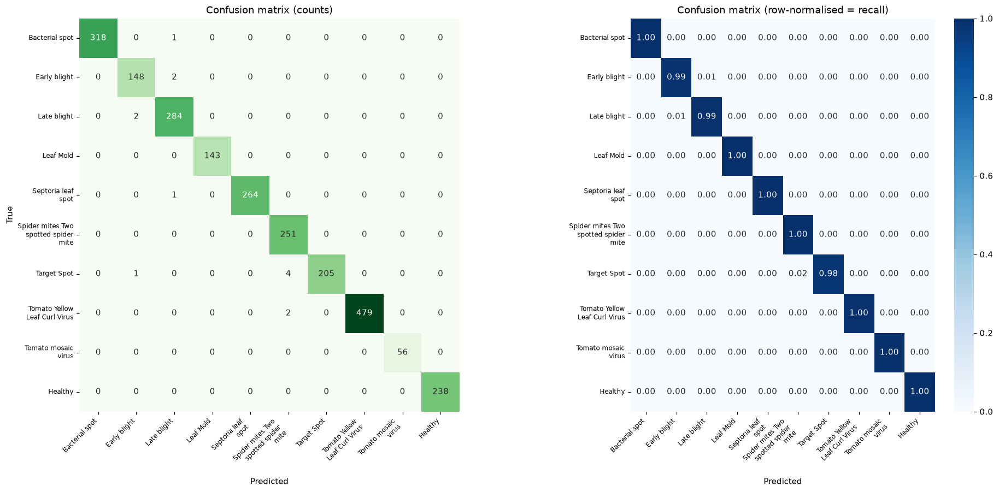

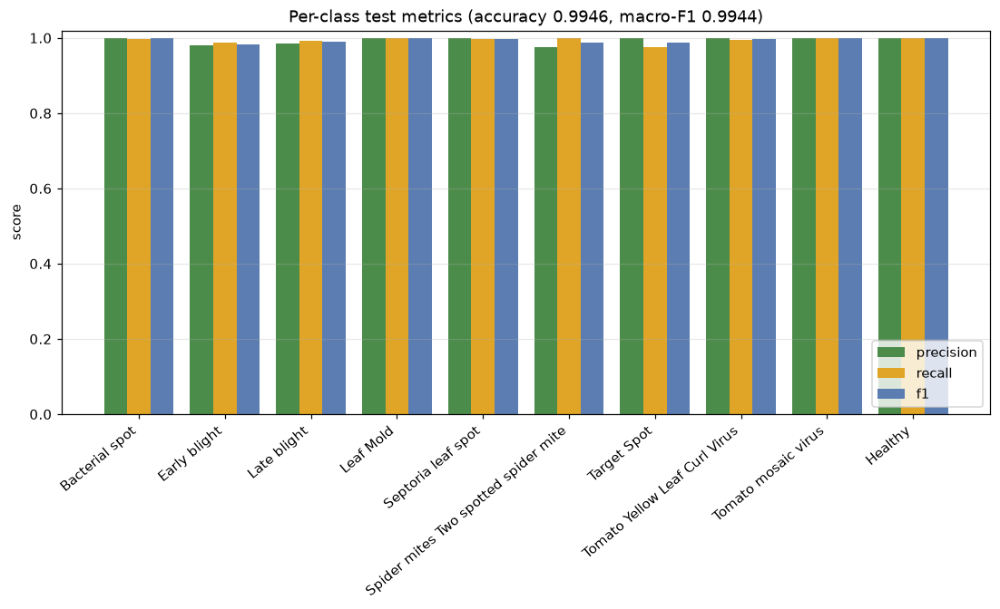

Most frequent confusions (true -> predicted):


,count,true,pred
0,4,Tomato__Target_Spot,Tomato_Spider_mites_Two_spotted_spider_mite
1,2,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato_Spider_mites_Two_spotted_spider_mite
2,2,Tomato_Late_blight,Tomato_Early_blight
3,2,Tomato_Early_blight,Tomato_Late_blight
4,1,Tomato__Target_Spot,Tomato_Early_blight
5,1,Tomato_Septoria_leaf_spot,Tomato_Late_blight
6,1,Tomato_Bacterial_spot,Tomato_Late_blight


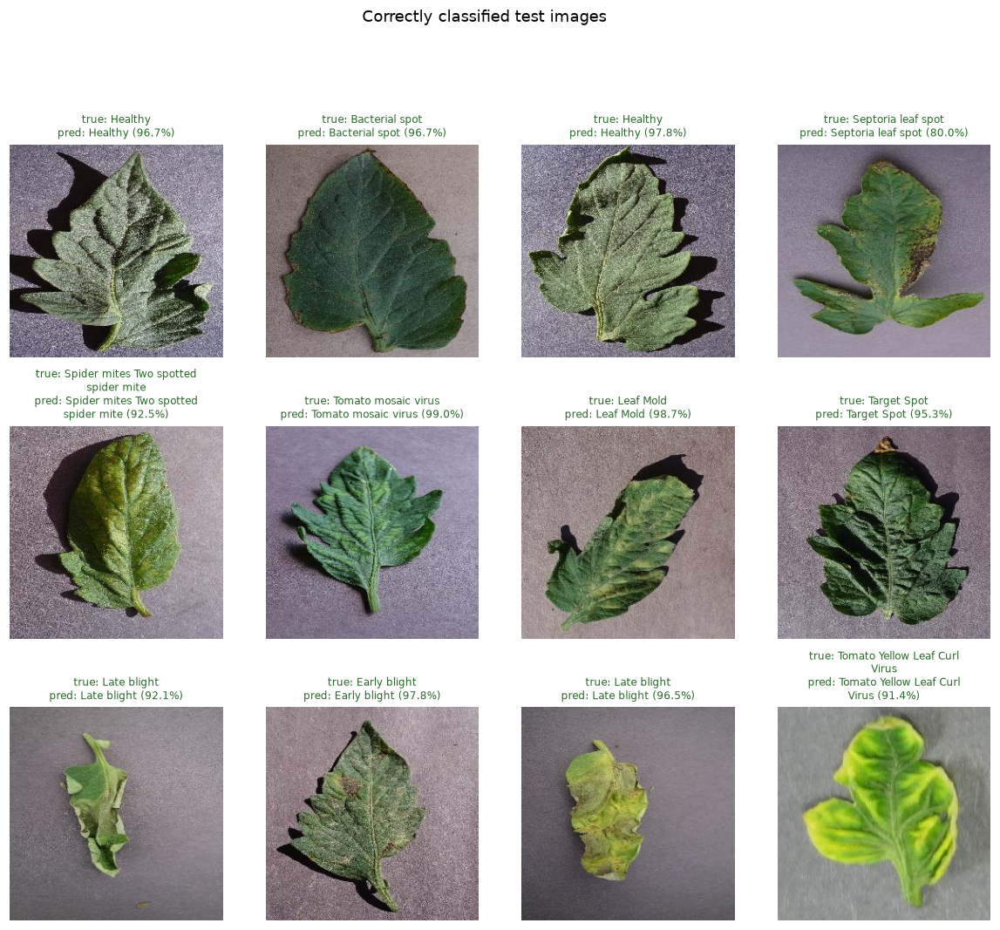

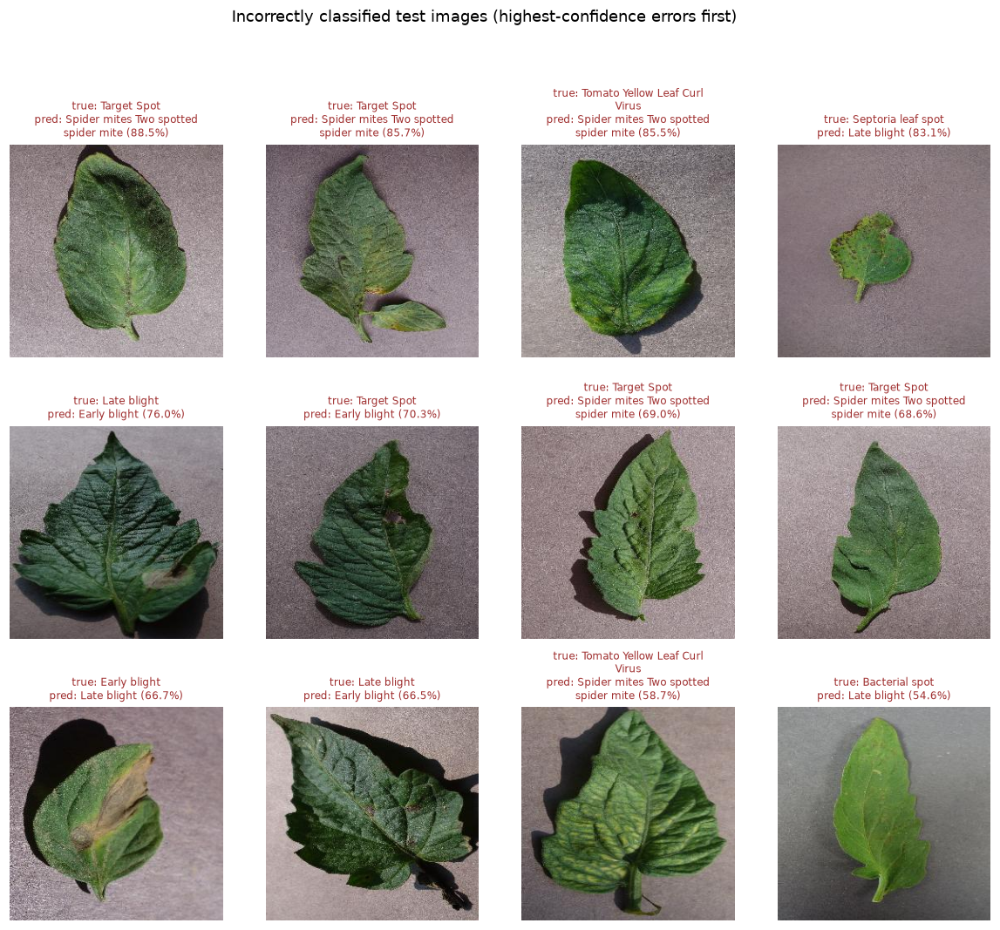

In [12]:
display(IPyImage(filename=str(RESULTS_DIR / "confusion_matrix.png"), width=1100))
display(IPyImage(filename=str(PLOTS_DIR / "per_class_metrics.png"), width=900))
print("Most frequent confusions (true -> predicted):")
display(pd.DataFrame(test_metrics["top_confusions"]))
display(IPyImage(filename=str(PLOTS_DIR / "correct_predictions.png"), width=900))
display(IPyImage(filename=str(PLOTS_DIR / "incorrect_predictions.png"), width=900))

## 14. Grad-CAM (explainable AI)

Grad-CAM hooks `layer4` (the last convolutional stage, 512×7×7). For the explained class *c* it computes
α<sub>k</sub> = mean of ∂y<sub>c</sub>/∂A<sup>k</sup>, then CAM = ReLU(Σ<sub>k</sub> α<sub>k</sub> A<sup>k</sup>),
up-samples it bilinearly to the input size, min-max normalises it to [0, 1] and overlays a `jet` colour map on
the original-resolution image. The explained class defaults to the predicted class and can be overridden.

**Scientific caveat.** Grad-CAM shows *which regions increased the class score*. It is a coarse (7×7 → upsampled)
attribution, not a lesion segmentation: it does not delineate individual bacterial spots. Pixel-accurate lesion
localisation would need an annotated segmentation dataset and a separate segmentation/detection model.

{'target_layer': 'layer4', 'n_blank': 0, 'n_uniform': 0, 'all_normalised': True, 'mean_cam_correlation_top1_vs_top2': 0.056101350836111084}


,true,pred,raw_max,norm_min,norm_max,norm_std,blank,uniform
0,Tomato_Bacterial_spot,Tomato_Bacterial_spot,0.140,0.0,1.0,0.251,False,False
1,Tomato_Early_blight,Tomato_Early_blight,0.157,0.0,1.0,0.213,False,False
2,Tomato_Late_blight,Tomato_Late_blight,0.143,0.0,1.0,0.238,False,False
3,Tomato_Leaf_Mold,Tomato_Leaf_Mold,0.155,0.0,1.0,0.196,False,False
4,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,0.130,0.0,1.0,0.227,False,False
5,Tomato_Spider_mites_Two_spotted_spider_mite,Tomato_Spider_mites_Two_spotted_spider_mite,0.135,0.0,1.0,0.158,False,False
6,Tomato__Target_Spot,Tomato__Target_Spot,0.119,0.0,1.0,0.284,False,False
7,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,0.115,0.0,1.0,0.223,False,False
8,Tomato__Tomato_mosaic_virus,Tomato__Tomato_mosaic_virus,0.268,0.0,1.0,0.245,False,False
9,Tomato_healthy,Tomato_healthy,0.126,0.0,1.0,0.191,False,False


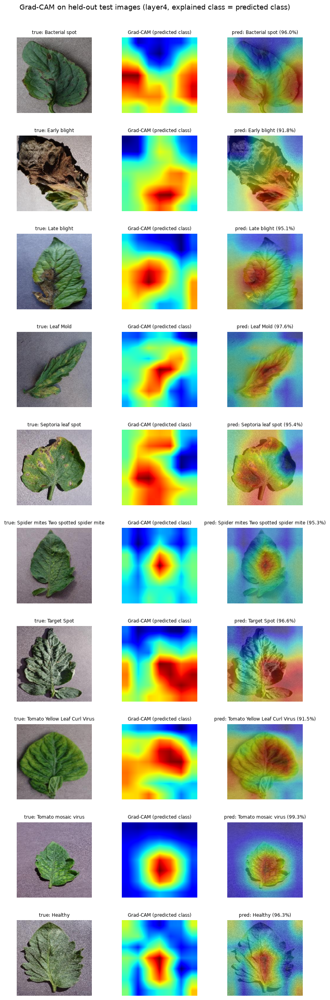

In [13]:
from src.gradcam import batch_examples, explain_image, gradcam_figure, class_specificity_check
from src.model import load_checkpoint

checks = batch_examples(n_per_class=1, seed=0, device=DEVICE)
print({k: v for k, v in checks.items() if k not in ("images", "class_specificity")})
display(pd.DataFrame(checks["images"])[["true", "pred", "raw_max", "norm_min", "norm_max", "norm_std", "blank", "uniform"]].round(3))
display(IPyImage(filename=str(PLOTS_DIR / "gradcam_examples.png"), width=750))

Predicted: Tomato_Bacterial_spot | sanity: {'raw_max': 0.15806284546852112, 'raw_nonzero_fraction': 1.0, 'norm_min': 0.0, 'norm_max': 1.0, 'norm_std': 0.25576215982437134, 'blank': False, 'uniform': False, 'normalised_correctly': True}
Specificity (top-1 vs top-2 CAM correlation): {'top1_idx': 0, 'top2_idx': 8, 'cam_correlation': 0.8454187271522638, 'mean_abs_difference': 0.12066000699996948}


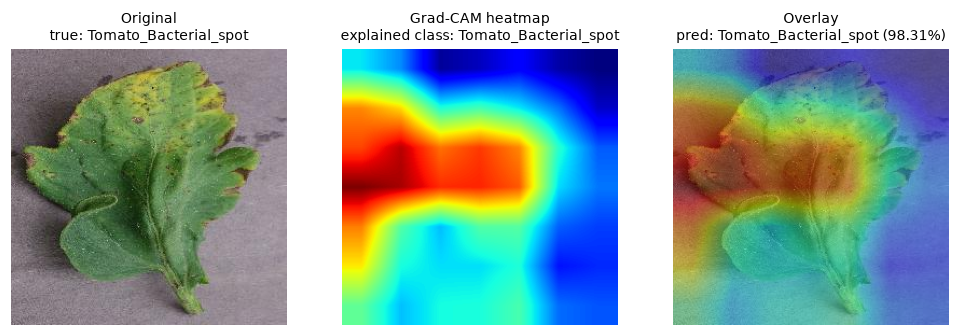

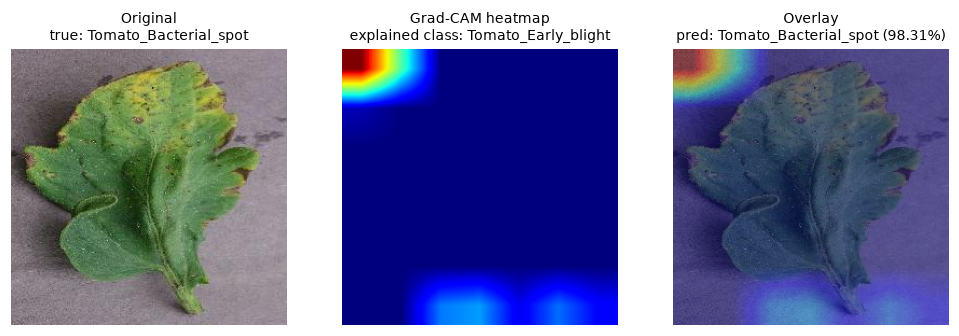

In [14]:
# Target-class selection: explain the predicted class vs. a user-chosen class on the same image.
trained_model, mapping, meta = load_checkpoint(MODELS_DIR / "best_model.pth", DEVICE)
classes = mapping["classes"]
example = sorted((PROJECT_ROOT / "examples").glob("*Bacterial*"))[0]
image = load_image(example)
res_pred = explain_image(trained_model, image, DEVICE)
other = [i for i in range(len(classes)) if i != res_pred["pred_idx"]][0]
res_other = explain_image(trained_model, image, DEVICE, target_class=other)
print("Predicted:", classes[res_pred["pred_idx"]], "| sanity:", res_pred["sanity"])
print("Specificity (top-1 vs top-2 CAM correlation):", class_specificity_check(trained_model, image, DEVICE))
fig = gradcam_figure(image, res_pred, classes, true_label="Tomato_Bacterial_spot"); display(fig); plt.close(fig)
fig = gradcam_figure(image, res_other, classes, true_label="Tomato_Bacterial_spot"); display(fig); plt.close(fig)

## 15. Unseen image prediction

`src.predict.Predictor` loads the checkpoint and class mapping once and applies exactly the inference transform.
The images in `examples/` are held-out **test** images (never seen in training or validation). Results are also
recorded in `results/unseen_notebook/unseen_predictions.csv`.

Tomato_Bacterial_spot.JPG                expected=Tomato_Bacterial_spot predicted=Tomato_Bacterial_spot conf=0.983
Tomato_Early_blight.JPG                  expected=Tomato_Early_blight predicted=Tomato_Early_blight conf=0.958
Tomato_Late_blight.JPG                   expected=Tomato_Late_blight predicted=Tomato_Late_blight conf=0.954
Tomato_Leaf_Mold.JPG                     expected=Tomato_Leaf_Mold predicted=Tomato_Leaf_Mold conf=0.971


Tomato_Septoria_leaf_spot.JPG            expected=Tomato_Septoria_leaf_spot predicted=Tomato_Septoria_leaf_spot conf=0.987
Tomato_Spider_mites_Two_spotted_spider_mite.JPG expected=Tomato_Spider_mites_Two_spotted_spider_mite predicted=Tomato_Spider_mites_Two_spotted_spider_mite conf=0.977
Tomato__Target_Spot.JPG                  expected=Tomato__Target_Spot predicted=Tomato__Target_Spot conf=0.977
Tomato__Tomato_YellowLeaf__Curl_Virus.JPG expected=Tomato__Tomato_YellowLeaf__Curl_Virus predicted=Tomato__Tomato_YellowLeaf__Curl_Virus conf=0.886


Tomato__Tomato_mosaic_virus.JPG          expected=Tomato__Tomato_mosaic_virus predicted=Tomato__Tomato_mosaic_virus conf=0.991
Tomato_healthy.JPG                       expected=Tomato_healthy predicted=Tomato_healthy conf=0.965


,image,expected,predicted,correct,confidence,top3
0,examples/Tomato_Bacterial_spot.JPG,Tomato_Bacterial_spot,Tomato_Bacterial_spot,True,0.9831,Bacterial spot=0.983; Tomato mosaic virus=0.00...
1,examples/Tomato_Early_blight.JPG,Tomato_Early_blight,Tomato_Early_blight,True,0.9583,Early blight=0.958; Tomato mosaic virus=0.010;...
2,examples/Tomato_Late_blight.JPG,Tomato_Late_blight,Tomato_Late_blight,True,0.9541,Late blight=0.954; Tomato mosaic virus=0.012; ...
3,examples/Tomato_Leaf_Mold.JPG,Tomato_Leaf_Mold,Tomato_Leaf_Mold,True,0.9714,Leaf Mold=0.971; Tomato mosaic virus=0.008; Sp...
4,examples/Tomato_Septoria_leaf_spot.JPG,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,True,0.9866,Septoria leaf spot=0.987; Tomato mosaic virus=...
5,examples/Tomato_Spider_mites_Two_spotted_spide...,Tomato_Spider_mites_Two_spotted_spider_mite,Tomato_Spider_mites_Two_spotted_spider_mite,True,0.9774,Spider mites Two spotted spider mite=0.977; To...
6,examples/Tomato__Target_Spot.JPG,Tomato__Target_Spot,Tomato__Target_Spot,True,0.9771,Target Spot=0.977; Tomato mosaic virus=0.006; ...
7,examples/Tomato__Tomato_YellowLeaf__Curl_Virus...,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,True,0.8859,Tomato Yellow Leaf Curl Virus=0.886; Bacterial...
8,examples/Tomato__Tomato_mosaic_virus.JPG,Tomato__Tomato_mosaic_virus,Tomato__Tomato_mosaic_virus,True,0.9914,Tomato mosaic virus=0.991; Early blight=0.001;...
9,examples/Tomato_healthy.JPG,Tomato_healthy,Tomato_healthy,True,0.9647,Healthy=0.965; Tomato mosaic virus=0.009; Earl...


Correct: 10/10


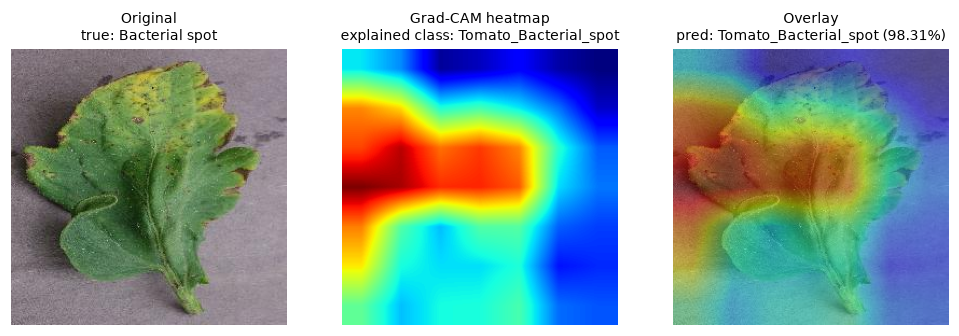

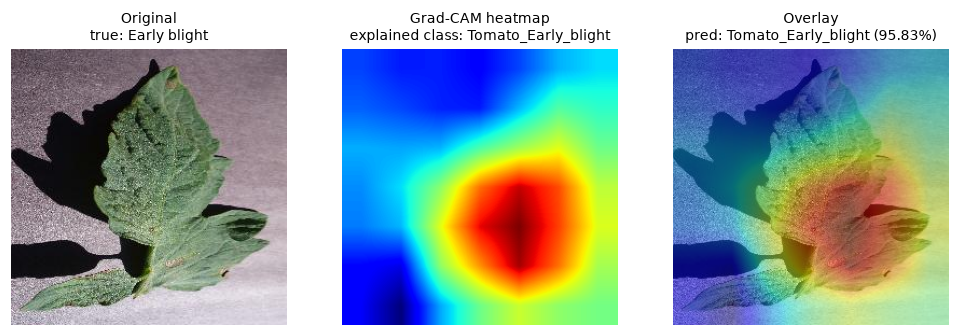

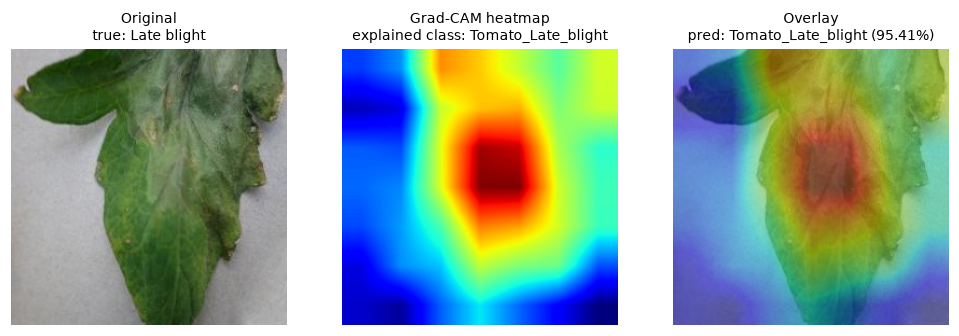

In [15]:
from src.predict import Predictor, run_on_images

predictor = Predictor(device=DEVICE)
example_paths = sorted((PROJECT_ROOT / "examples").glob("*.JPG"))
expected = [p.stem for p in example_paths]
unseen_df = run_on_images(example_paths, expected, RESULTS_DIR / "unseen_notebook", predictor)
display(unseen_df[["image", "expected", "predicted", "correct", "confidence", "top3"]])
print(f"Correct: {int(unseen_df.correct.sum())}/{len(unseen_df)}")
for fig_path in unseen_df.gradcam_figure.head(3):
    display(IPyImage(filename=str(PROJECT_ROOT / fig_path), width=800))

## 16. Conclusion

* A ResNet18 feature extractor (ImageNet-pretrained, `layer3`/`layer4` fine-tuned) with a 512→256→C MLP head was
  trained on 16011 PlantVillage tomato leaf images across
  10 classes using Apple MPS.
* Held-out **test accuracy 0.9946** and **macro-F1 0.9944** on 2399 images
  (13 errors; see Section 12 for the full table); the checkpoint was chosen on validation macro-F1 only.
* Grad-CAM sanity checks over one test image per class: 0 blank maps,
  0 uniform maps, all normalised = True, mean top-1 vs top-2
  CAM correlation 0.056 (class-specific). The maps concentrate on
  leaf tissue and symptomatic regions, but they are attribution maps, not lesion segmentations.
* Limitations: PlantVillage images are lab-style single leaves on plain backgrounds, so field performance will be
  lower; the near-duplicate structure of the dataset makes benchmark numbers optimistic even with grouped
  splitting; the model only knows these 10 classes and will still output a
  class for unrelated images.
* See `PROJECT_REPORT.md` for the complete write-up.